# Bayesian analysis - arrays of posteriors


## Introduction
This is an attempt at an alternative model for the analysis of football scoring ability, from the book Bayesian Analysis with Python

The book's example Notebook is at [https://github.com/aloctavodia/BAP3/blob/main/code_updated/Chp_03.ipynb]

## Implementation
### Imports

In [1]:
import pathlib

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import preliz as pz
import pymc as pm

----------------------------

## Data load

In [2]:
path = pathlib.Path("data/football_players.csv")
df = pd.read_csv(path)
df.head(2)

,name,position,goals,shots
0,Aaron Connolly,FW,5,59
1,Aaron Cresswell,DF,4,69


------------------------

## Helper functions 

In [3]:
def plot_dist(dist, ax):
    """
    plot_dist: plots PyMC known distribution (eg Beta) on Matplotlib axes
    """
    draws = pm.draw(dist, draws=5000, random_seed=42)
    ax.hist(
        draws,
        alpha=0.1,
        density=True,
        bins=100,
        label="PyMC draws",
    )
    ax.set_xlabel("Value")
    ax.set_ylabel("Density")
    ax.set_title("PyMC Distribution Draw")
    ax.legend()


# end plot_dist

In [4]:
def beta_ab_to_mn(alpha, beta):
    """
    beta_ab_to_mn: converts beta distribution parameters
    """

    nu = alpha + beta
    mu = alpha / nu
    return (mu, nu)


# end beta_ab_to_mn


def beta_mn_to_ab(mu, nu):
    """
    beta_ab_to_mn: converts beta distribution parameters
    """

    alpha = mu * nu
    beta = (1 - mu) * nu
    return (alpha, beta)


# end beta_mn_to_ab(mu, nu)

--------------------------

## Build the model

### Prior definition

For this notebook, I decided to model the goal scoring ability of football players, by assuming goal scoring from a shot was Binomial process.  That is, the probability of scoring a goal from a shot was constant, and independent.  Here the variable _theta_ holds that distribution, being an array of distributions, one for each player in the data-set.

One key decision was to not group the players into meaning full groups (i.e. Midfielders, Forwards, etc), even though that grouping information was in the data-set.  I was more concerned with learning how to manage arrays of posteriors.

For Bayesian analysis, you have to specify your prior beliefs as the probability of scoring a goal from a shot. To provide an extreme example, I chose to have a completely flat prior.  Now some might argue that this is ridiculous - no player ever gets close to scoring 100% form shots at goal, but I don't know much about soccer.

In [5]:
# have completely uninformative prior (flat line)
alpha = 1
beta = 1

mu, nu = beta_ab_to_mn(alpha, beta)

n_players = len(df)

Plot the assumed prior distribution, and how __PyMC__ sees the distribution

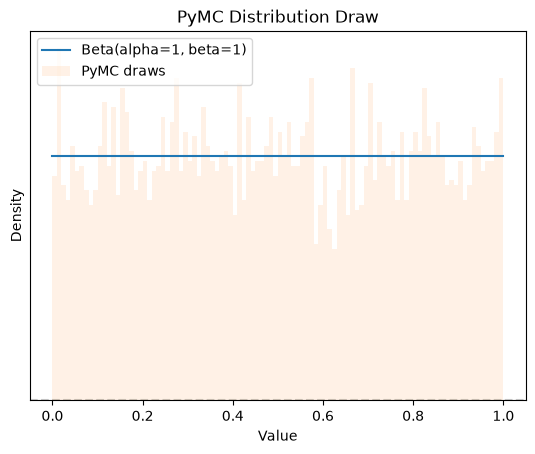

In [6]:
alpha, beta = beta_mn_to_ab(mu, nu)

# plot using preliz
ax = pz.Beta(alpha=alpha, beta=beta).plot_pdf()

# plot what PyMC sees
dist = pm.Beta.dist(alpha=alpha, beta=beta)
plot_dist(dist, ax)

----------------------

### Specify and run the model

We declare that we want _PyMC_ to create an array the _theta_ posteriors, and then use the data-set to adjust each posterior.

We ignore the maths library warning messages.

In [7]:
with pm.Model() as model_1:
    theta = pm.Beta("theta", mu=mu, nu=nu, shape=n_players)
    _ = pm.Binomial("gs", n=df["shots"].values, p=theta, observed=df["goals"].values)
    idata_1 = pm.sample()
# end with

C:\Users\donrc\anaconda3\envs\bayes_env\Lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
NUTS[nutpie]: [theta]


Output()

----------------

### Inspect model performance


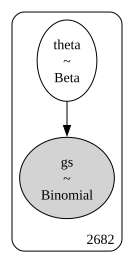

In [8]:
pm.model_to_graphviz(model_1)

In [9]:
problems = az.diagnose(idata_1)

Divergences
No divergent transitions found.

E-BFMI
E-BFMI satisfactory for all chains.

ESS
Effective sample size satisfactory for all parameters.

R-hat
The following parameters have R-hat values greater than 1.01:
  theta
Such high values indicate incomplete mixing and biased estimation.
You should consider regularizing your model with additional prior information or a more effective parameterization.


-------------------------

### Inspect results

First get a statistical summary, and look at the first two players

In [10]:
summary = az.summary(idata_1)

summary.head(2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
theta[0],0.099,0.039,0.046,0.17,5493,2915,1.00,0.00052,0.00067
theta[1],0.0703,0.029,0.031,0.12,5853,3037,1.00,0.00037,0.00052


Look at last two players

In [11]:
summary.tail(2)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
theta[2680],0.091,0.06,0.019,0.2,4736,2539,1.00,0.00082,0.0012
theta[2681],0.121,0.064,0.038,0.24,5910,2533,1.00,0.0008,0.0012


We can use the summary to extract the assessed goals per shot for the player number 2860

In [12]:
summary.loc["theta[2680]", "mean"]

np.float64(0.09070522101359112)

Review the structure of the results of the model fitting process

In [13]:
idata_1

<xarray.DataTree>
Group: /
├── Group: /posterior
│       Dimensions:      (chain: 4, draw: 1000, theta_dim_0: 2682)
│       Coordinates:
│         * chain        (chain) int64 32B 0 1 2 3
│         * draw         (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * theta_dim_0  (theta_dim_0) int64 21kB 0 1 2 3 4 ... 2677 2678 2679 2680 2681
│       Data variables:
│           theta        (chain, draw, theta_dim_0) float64 86MB 0.1151 ... 0.06763
│       Attributes:
│           created_at:                 2026-10-13T02:15:51.523683+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
│           inference_library:          nutpie
│           inference_library_version:  0.16.11
│           sampling_time:              13.068703413009644
│           tuning_steps:               400
├── Group: /sample_stats
│       Dimensions:                   (chain: 4, draw: 1000)
│       Coordinates:
│         * chain                     (chain) int64 32B 0 1 2 3
│         * draw                      (draw) int64 8kB 0 1 2 3 4 ... 995 996 997 998 999
│       Data variables: (12/20)
│           depth                     (chain, draw) uint64 32kB 5 5 5 5 5 ... 5 4 4 5 5
│           maxdepth_reached          (chain, draw) bool 4kB False False ... False False
│           step_size                 (chain, draw) float64 32kB 0.2079 ... 0.2181
│           transformation_update_id  (chain, draw) int64 32kB 0 0 0 0 0 0 ... 0 0 0 0 0
│           step_size_bar             (chain, draw) float64 32kB 0.2026 ... 0.2102
│           mean_tree_accept          (chain, draw) float64 32kB 0.9199 ... 0.7986
│           ...                        ...
│           fisher_distance           (chain, draw) float64 32kB 443.3 414.0 ... 358.9
│           transformation_index      (chain, draw) int64 32kB 338 338 338 ... 338 338
│           diverging                 (chain, draw) bool 4kB False False ... False False
│           divergence_draw           (chain, draw) uint64 32kB 0 0 0 0 0 ... 0 0 0 0 0
│           divergence_message        (chain, draw) object 32kB None None ... None None
│           divergence_energy_error   (chain, draw) float64 32kB nan nan nan ... nan nan
│       Attributes:
│           created_at:                  2026-10-13T02:15:51.465692+00:00
│           creation_library:            ArviZ
│           creation_library_version:    1.3.0
│           creation_library_language:   Python
│           sample_dims:                 ['chain', 'draw']
│           inference_library:           nutpie
│           inference_library_version:   0.16.11
│           inference_library_settings:  {"sampler": "nuts", "adaptation": "diag", "s...
├── Group: /constant_data
│       Attributes:
│           created_at:                 2026-10-13T02:15:51.515667+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.0
│           creation_library_language:  Python
│           inference_library:          pymc
│           inference_library_version:  6.3.1
│           sample_dims:                []
└── Group: /observed_data
        Dimensions:   (gs_dim_0: 2682)
        Coordinates:
          * gs_dim_0  (gs_dim_0) int64 21kB 0 1 2 3 4 5 ... 2677 2678 2679 2680 2681
        Data variables:
            gs        (gs_dim_0) int64 21kB 5 4 3 1 10 7 0 16 2 ... 0 3 1 1 2 12 13 1 2
        Attributes:
            created_at:                 2026-10-13T02:15:51.520155+00:00
            creation_library:           ArviZ
            creation_library_version:   1.3.0
            creation_library_language:  Python
            inference_library:          pymc
            inference_library_version:  6.3.1
            sample_dims:                []

-----------------

## Visualize the results

_ArviZ_ allows you to index into an array of distributions by the _coord_ parameter.  The name _theta_dim_0_ is an internally generated name for the dimension that indexes into the distribution array.

Here we plot the posterior distribution for player 1457 (Messi)

In [14]:
df.loc[1457, :]

name        Lionel Messi
position              FW
goals                125
shots                720
Name: 1457, dtype: object

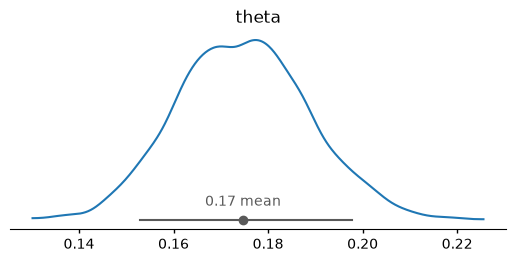

In [15]:
pc = az.plot_dist(idata_1, var_names="theta", coords={"theta_dim_0": 1457})

We can also use Matplotlib explicitly by getting the distribution as data array

In [16]:
samples = idata_1.posterior["theta"].sel(theta_dim_0=1457).values.flatten()

Now plot the data array

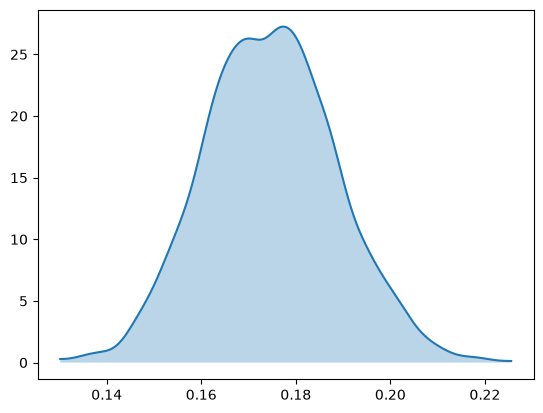

In [17]:
x, y, c = az.kde(samples)

# plot them directly with matplotlib
plt.plot(x, y)
plt.fill_between(x, y, alpha=0.3)
plt.show()

-------------------

### Examining player variation

If we plot the distributions for the first 10 players in our data set, we get some illuminating results

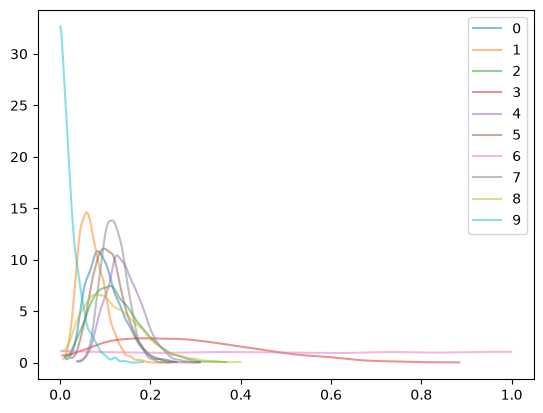

In [18]:
fig, ax = plt.subplots()

for row in range(10):
    samples = idata_1.posterior["theta"].sel(theta_dim_0=row).values.flatten()
    x, y, c = az.kde(samples)
    ax.plot(
        x,
        y,
        alpha=0.5,
        label=str(row),
    )
# end for
ax.legend()

We see:

- Player 9 (see table below) had no goals at all from 37 shots, so the bulk of his distribution is near 0.0
- Player 6 (see table below) had no shots at goal, so the posterior and prior are identical.  No shots at goal is to be expected for a Goalkeeper, but a counter intuitive posterior
- Player 3 (see table below) had a small number of  shots at goal, but got 20% of them in, so his mean is 20%, but with a very wide uncertainty

#### Table of first 10 player details

In [19]:
df.head(10)

,name,position,goals,shots
0,Aaron Connolly,FW,5,59
1,Aaron Cresswell,DF,4,69
2,Aaron Hunt,MF,3,30
3,Aaron Lennon,MF,1,5
4,Aaron Leya Iseka,FW,10,76
5,Aaron Mooy,MF,7,72
6,Aaron Ramsdale,GK,0,0
7,Aaron Ramsey,MF,16,141
8,Aaron Wan-Bissaka,DF,2,23
9,Aarón Martín,DF,0,37


----------------------------

## Visualization of model

We first build a list of player names to use as labels in the plots below

In [20]:
names = df.loc[:, "name"].values.tolist()



We plot the first 10 of our posterior distribution for _theta_ (the goals per shot figure)

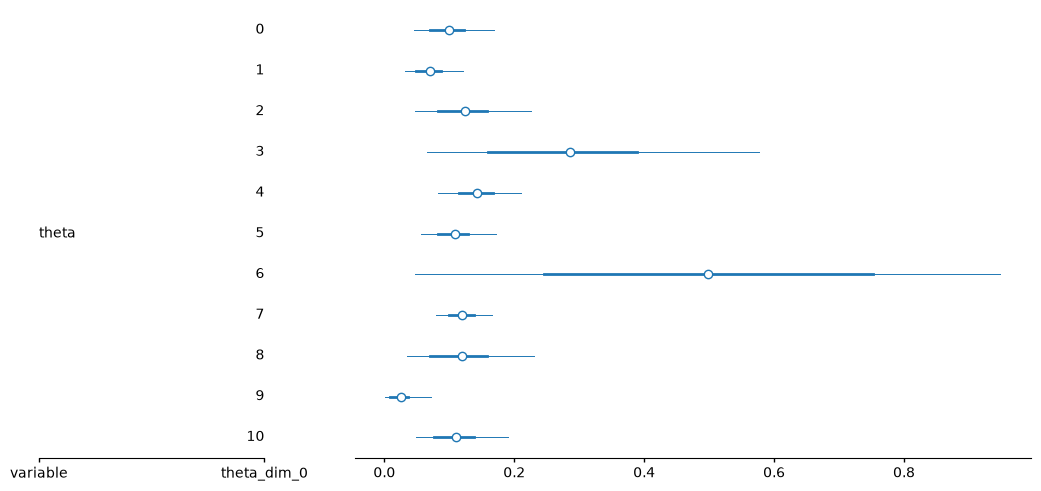

In [21]:
pc = az.plot_forest(
    idata_1,
    var_names=["theta"],
    combined=True,
    coords={"theta_dim_0": slice(0, 10)},
)

We can also plot a random sample of posteriors

get the random sample index values

In [22]:
n_samples = 10
rng = np.random.default_rng(seed=42)
random_indices = rng.choice(len(df), size=n_samples, replace=False)
random_indices = sorted(random_indices)
[int(n) for n in random_indices]

[230, 238, 252, 540, 1159, 1174, 1750, 1868, 2069, 2299]

Plot the posterior distributions index by our random sample

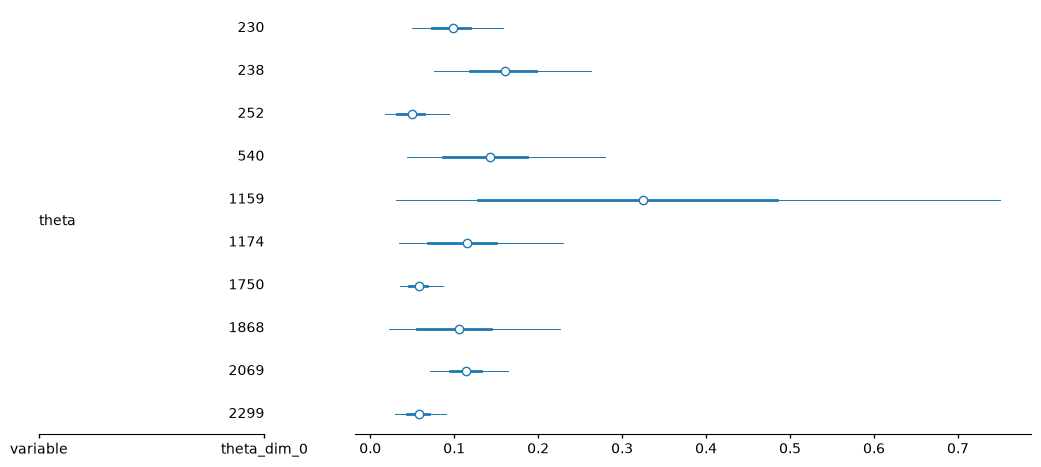

In [23]:
pc = az.plot_forest(
    idata_1,
    var_names=["theta"],
    combined=True,
    coords={"theta_dim_0": random_indices},
)

#### Better labels for each posterior

We map the index of the posterior distribution (0,1,2, ...) to the name of the player

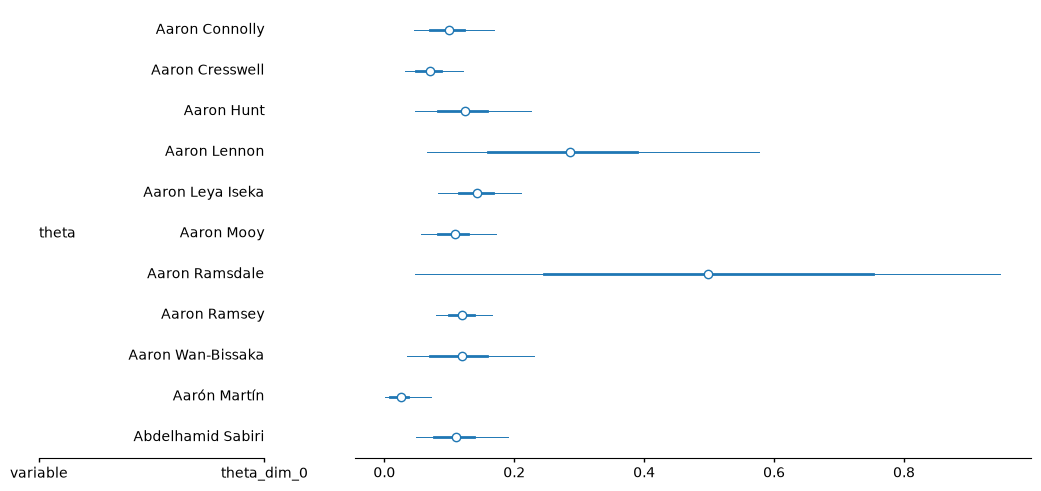

In [24]:
rename_map = {i: name for i, name in enumerate(names)}
labeller = az.labels.MapLabeller(coord_map={"theta_dim_0": rename_map})

pc = az.plot_forest(
    idata_1,
    var_names=["theta"],
    combined=True,
    coords={"theta_dim_0": slice(0, 10)},
    labeller=labeller,
)

Now clean up the chart junk on the left hand x axis, by diving down to _Matplotlib_

[]

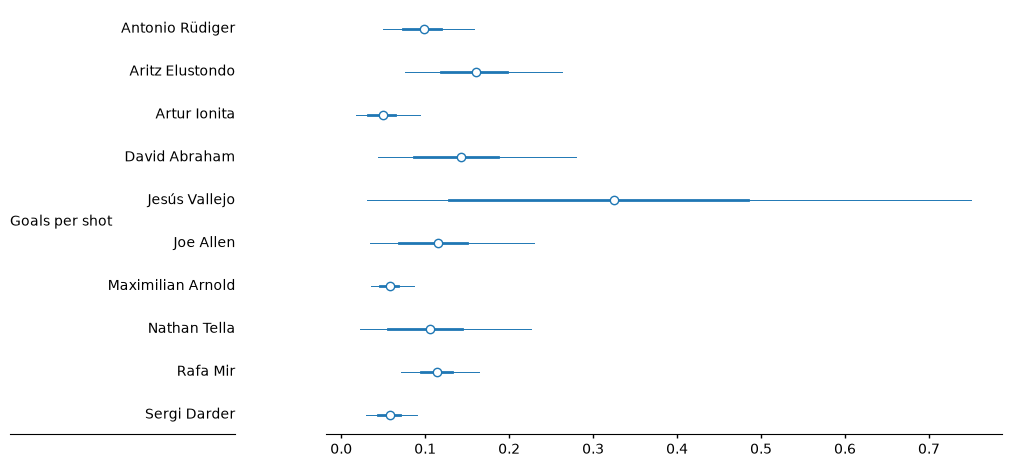

In [25]:
rename_map = {i: name for i, name in enumerate(names)}
var_map = {"theta": "Goals per shot"}


labeller = az.labels.MapLabeller(
    coord_map={"theta_dim_0": rename_map},
    var_name_map=var_map,
)

pc = az.plot_forest(
    idata_1,
    var_names=["theta"],
    combined=True,
    coords={"theta_dim_0": random_indices},
    labeller=labeller,
)

# clear x axis of left panel
pc.viz.figure.item().axes[0].set_xticks([])

### Ridge plot

an alternative way of show individual posteriors

[]

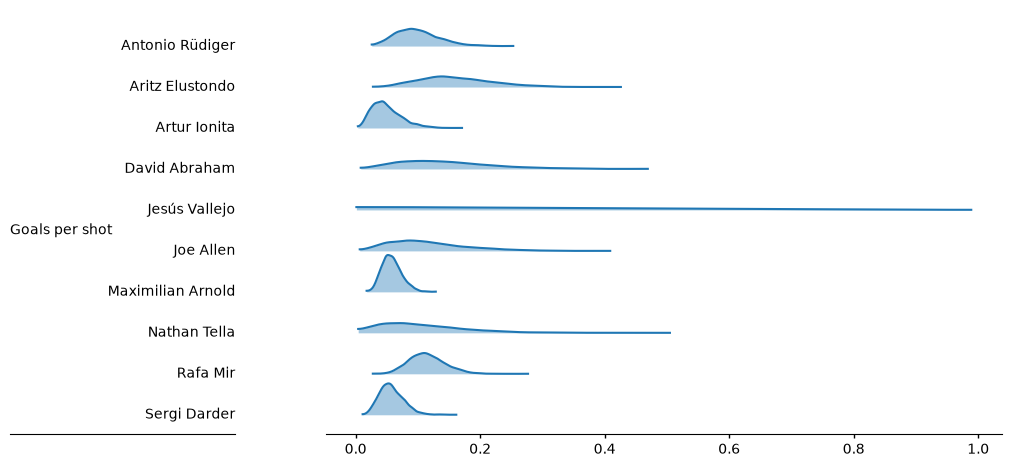

In [26]:
pc = az.plot_ridge(
    idata_1,
    var_names=["theta"],
    combined=True,
    coords={"theta_dim_0": random_indices},
    labeller=labeller,
)
# clear x axis of left panel
pc.viz.figure.item().axes[0].set_xticks([])

-----------------------

### Comparison of posterior with prior distributions

We look at first 10 players, and then the first player

First, get prior samples, and add to data-tree

In [27]:
with model_1:
    # Sample prior
    prior_samples = pm.sample_prior_predictive()
# end with

idata_1.update(prior_samples)

Sampling: [gs, theta]


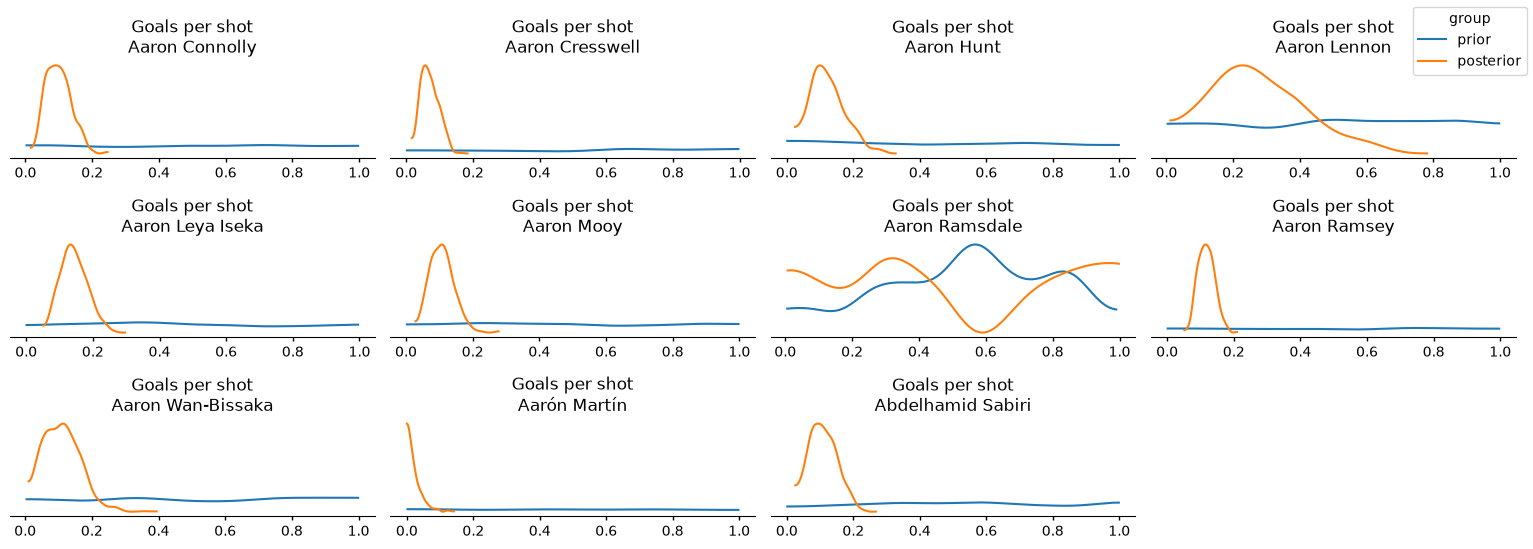

In [28]:
az.plot_prior_posterior(
    idata_1,
    var_names=["theta"],
    kind="kde",
    coords={"theta_dim_0": slice(0,10)},
    labeller=labeller,
)
plt.tight_layout()

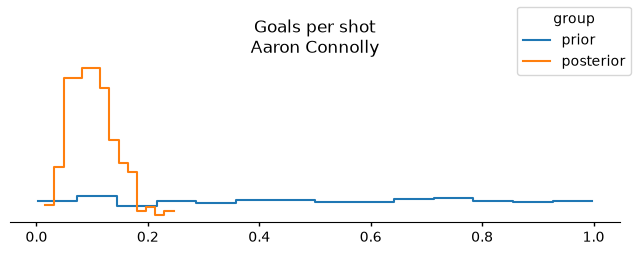

In [29]:
az.plot_prior_posterior(
    idata_1,
    var_names=["theta"],
    kind="hist",
    coords={"theta_dim_0": [0]},
    labeller=labeller,
)
plt.tight_layout()

The sampling for a Goalkeeper with zero shots seems a little suspect.

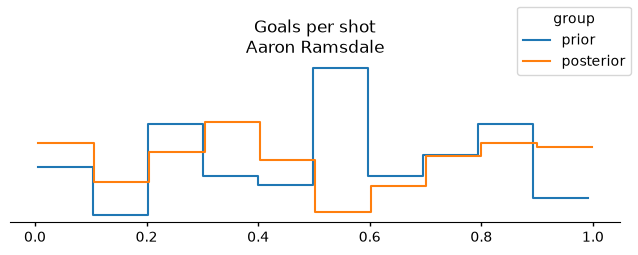

In [30]:
az.plot_prior_posterior(
    idata_1,
    var_names=["theta"],
    kind="hist",
    coords={"theta_dim_0": [6]},
    labeller=labeller,
)
plt.tight_layout()

------------------------------

## Conclusions



My choice of priors I now think was sub-optimal: I should have had a distribution weighted away from 1.0, more towards 0.1 (the data-set overall average).  It is still interesting as to what the analysis gives with a completely uninformative prior

-----------------------------

## Reproducibility

In [31]:
%load_ext watermark

In [32]:
%watermark

Last updated: 2026-10-13T12:16:35.482416+10:00

Python implementation: CPython
Python version       : 3.14.7
IPython version      : 9.17.1

Compiler    : MSC v.1944 64 bit (AMD64)
OS          : Windows
Release     : 11
Machine     : AMD64
Processor   : Intel64 Family 6 Model 170 Stepping 4, GenuineIntel
CPU cores   : 22
Architecture: 64bit



In [33]:
%watermark -h -iv -co

conda environment: bayes_env

Hostname: INSPIRON16

arviz     : 1.3.0
matplotlib: 3.11.1
numpy     : 2.4.6
pandas    : 3.0.5
preliz    : 0.28.0
pymc      : 6.3.1

